Import data for Visa and SandP500 prices since 1-1-2021 to 9-27-26

In [116]:
import yfinance as yf
import pandas as pd

ticker = 'V'
market = '^Gspc' #SandP500 

data = yf.download([ticker, market], start = '2021-1-1', 
                   end = '2026-9-27', auto_adjust = True) # Get data from the past 5 years of market and visa history


[*********************100%***********************]  2 of 2 completed


Calculate monthly returns for the data.

In [117]:
prices = data['Close']
monthly_prices = prices.resample("ME").last()
returns = monthly_prices.pct_change()
print(returns.head())

Ticker             V     ^GSPC
Date                          
2021-01-31       NaN       NaN
2021-02-28  0.100749  0.026091
2021-03-31 -0.003108  0.042439
2021-04-30  0.103103  0.052425
2021-05-31 -0.025389  0.005486


Get rid of the NaN amount for the first month that doesnt have percent change.
Rename V and Gspc columns to Stock and Market.

In [118]:
returns = returns.dropna()
returns.columns = ['Stock', 'Market']

Show the data characteristics to make sure everything is accurate.

In [119]:
print(returns.describe())

           Stock     Market
count  68.000000  68.000000
mean    0.011674   0.011796
std     0.056685   0.043502
min    -0.105984  -0.093396
25%    -0.032147  -0.011545
50%     0.007620   0.019632
75%     0.050196   0.042732
max     0.166113   0.104233


Set up the regression.

In [120]:
import statsmodels.api as sm

In [121]:
X = returns['Market']
Y = returns['Stock']

Run regression.

In [122]:
model = sm.OLS(Y, X).fit()

Output

In [123]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                  Stock   R-squared (uncentered):                   0.380
Model:                            OLS   Adj. R-squared (uncentered):              0.371
Method:                 Least Squares   F-statistic:                              41.04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):                    1.72e-08
Time:                        15:12:35   Log-Likelihood:                          114.00
No. Observations:                  68   AIC:                                     -226.0
Df Residuals:                      67   BIC:                                     -223.8
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

Show beta

In [124]:
Beta = model.params['Market']
print(f"The beta is: {Beta:.2f}")

The beta is: 0.79


Plot regression visually

In [125]:
import seaborn as sns
import matplotlib.pyplot as plt

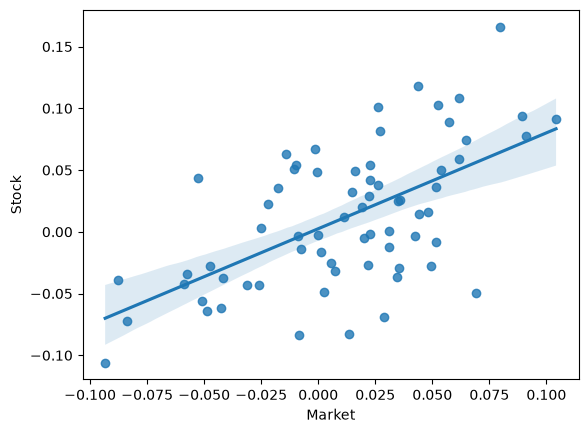

In [126]:
sns.regplot(x='Market', y='Stock', data=returns)
plt.show()